In [6]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
print("✅ Импорты OK")

✅ Импорты OK


In [7]:
load_dotenv()

DB_USER = os.getenv("DB_USER")
DB_PASS = os.getenv("DB_PASS")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")

engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

with engine.connect() as conn:
    result = conn.execute(text("SELECT version();"))
    row = result.fetchone()
    print("✅ Подключение успешно!")
    print(row[0])

✅ Подключение успешно!
PostgreSQL 16.15, compiled by Visual C++ build 1944, 64-bit


In [8]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv()

engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASS')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)

with engine.connect() as conn:
    print("✅ Подключение успешно!")
    print(conn.execute(text("SELECT version();")).fetchone()[0])

✅ Подключение успешно!
PostgreSQL 16.15, compiled by Visual C++ build 1944, 64-bit


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

print("Библиотеки для анализа загружены")

Библиотеки для анализа загружены


In [10]:
df = pd.read_csv("../data/HeartDiseaseTrain-Test.csv")
print("Размер:", df.shape)
df.head()

Размер: (1025, 14)


,age,sex,chest_pain_type,resting_blood_pressure,cholestoral,fasting_blood_sugar,rest_ecg,Max_heart_rate,exercise_induced_angina,oldpeak,slope,vessels_colored_by_flourosopy,thalassemia,target
0,52,Male,Typical angina,125,212,Lower than 120 mg/ml,ST-T wave abnormality,168,No,1.0,Downsloping,Two,Reversable Defect,0
1,53,Male,Typical angina,140,203,Greater than 120 mg/ml,Normal,155,Yes,3.1,Upsloping,Zero,Reversable Defect,0
2,70,Male,Typical angina,145,174,Lower than 120 mg/ml,ST-T wave abnormality,125,Yes,2.6,Upsloping,Zero,Reversable Defect,0
3,61,Male,Typical angina,148,203,Lower than 120 mg/ml,ST-T wave abnormality,161,No,0.0,Downsloping,One,Reversable Defect,0
4,62,Female,Typical angina,138,294,Greater than 120 mg/ml,ST-T wave abnormality,106,No,1.9,Flat,Three,Fixed Defect,0


In [11]:
df.dtypes

age                                int64
sex                                  str
chest_pain_type                      str
resting_blood_pressure             int64
cholestoral                        int64
fasting_blood_sugar                  str
rest_ecg                             str
Max_heart_rate                     int64
exercise_induced_angina              str
oldpeak                          float64
slope                                str
vessels_colored_by_flourosopy        str
thalassemia                          str
target                             int64
dtype: object

In [12]:
for col in df.select_dtypes(include='object').columns:
    print(f"{col}: {df[col].unique()}")

sex: <StringArray>
['Male', 'Female']
Length: 2, dtype: str
chest_pain_type: <StringArray>
['Typical angina', 'Atypical angina', 'Non-anginal pain', 'Asymptomatic']
Length: 4, dtype: str
fasting_blood_sugar: <StringArray>
['Lower than 120 mg/ml', 'Greater than 120 mg/ml']
Length: 2, dtype: str
rest_ecg: <StringArray>
['ST-T wave abnormality', 'Normal', 'Left ventricular hypertrophy']
Length: 3, dtype: str
exercise_induced_angina: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
slope: <StringArray>
['Downsloping', 'Upsloping', 'Flat']
Length: 3, dtype: str
vessels_colored_by_flourosopy: <StringArray>
['Two', 'Zero', 'One', 'Three', 'Four']
Length: 5, dtype: str
thalassemia: <StringArray>
['Reversable Defect', 'Fixed Defect', 'Normal', 'No']
Length: 4, dtype: str


D:\TEMP\USER\ipykernel_16800\1278731123.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [13]:
# Кодируем текстовые столбцы в числа

df['sex'] = df['sex'].map({'Female': 0, 'Male': 1})

df['chest_pain_type'] = df['chest_pain_type'].map({
    'Typical angina': 0,
    'Atypical angina': 1,
    'Non-anginal pain': 2,
    'Asymptomatic': 3
})

df['fasting_blood_sugar'] = df['fasting_blood_sugar'].map({
    'Lower than 120 mg/ml': 0,
    'Greater than 120 mg/ml': 1
})

df['rest_ecg'] = df['rest_ecg'].map({
    'Normal': 0,
    'ST-T wave abnormality': 1,
    'Left ventricular hypertrophy': 2
})

df['exercise_induced_angina'] = df['exercise_induced_angina'].map({
    'No': 0, 'Yes': 1
})

df['slope'] = df['slope'].map({
    'Upsloping': 0, 'Flat': 1, 'Downsloping': 2
})

df['vessels_colored_by_flourosopy'] = df['vessels_colored_by_flourosopy'].map({
    'Zero': 0, 'One': 1, 'Two': 2, 'Three': 3, 'Four': 4
})

df['thalassemia'] = df['thalassemia'].map({
    'Normal': 0, 'Fixed Defect': 1, 'Reversable Defect': 2, 'No': 3
})

print("✅ Кодировка завершена")
df.dtypes

✅ Кодировка завершена


age                                int64
sex                                int64
chest_pain_type                    int64
resting_blood_pressure             int64
cholestoral                        int64
fasting_blood_sugar                int64
rest_ecg                           int64
Max_heart_rate                     int64
exercise_induced_angina            int64
oldpeak                          float64
slope                              int64
vessels_colored_by_flourosopy      int64
thalassemia                        int64
target                             int64
dtype: object

In [14]:
df = df.rename(columns={
    'chest_pain_type': 'cp',
    'resting_blood_pressure': 'trestbps',
    'cholestoral': 'chol',
    'fasting_blood_sugar': 'fbs',
    'rest_ecg': 'restecg',
    'Max_heart_rate': 'thalach',
    'exercise_induced_angina': 'exang',
    'vessels_colored_by_flourosopy': 'ca',
    'thalassemia': 'thal'
})

print("✅ Столбцы переименованы")
print(df.columns.tolist())

✅ Столбцы переименованы
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [15]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [16]:
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,2,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,2,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,2,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,2,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,1,0


In [17]:
df = df.drop_duplicates()
print("После удаления дубликатов:", df.shape)

После удаления дубликатов: (302, 14)


In [18]:
df.to_sql("patients", engine, if_exists="replace", index=False)
print("✅ Таблица patients загружена в Postgres")

✅ Таблица patients загружена в Postgres


In [19]:
pd.read_sql("SELECT * FROM patients LIMIT 5", engine)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,2,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,2,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,2,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,2,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,1,0


In [20]:
pd.read_sql("SELECT COUNT(*) AS n, MIN(age) AS min_age, MAX(age) AS max_age FROM patients", engine)

,n,min_age,max_age
0,302,29,77


In [21]:
sql_script = """
CREATE TABLE IF NOT EXISTS sex_dict (
    code INT PRIMARY KEY,
    label TEXT NOT NULL
);

INSERT INTO sex_dict (code, label) VALUES
    (0, 'Female'), (1, 'Male')
ON CONFLICT (code) DO NOTHING;

CREATE TABLE IF NOT EXISTS cp_dict (
    code INT PRIMARY KEY,
    label TEXT NOT NULL
);

INSERT INTO cp_dict (code, label) VALUES
    (0, 'Typical angina'), (1, 'Atypical angina'),
    (2, 'Non-anginal pain'), (3, 'Asymptomatic')
ON CONFLICT (code) DO NOTHING;
"""

from sqlalchemy import text

with engine.begin() as conn:
    conn.execute(text(sql_script))

print("✅ Справочники созданы")

✅ Справочники созданы


In [22]:
print("sex_dict:")
print(pd.read_sql("SELECT * FROM sex_dict", engine))

print("\ncp_dict:")
print(pd.read_sql("SELECT * FROM cp_dict", engine))

sex_dict:
   code   label
0     0  Female
1     1    Male

cp_dict:
   code             label
0     0    Typical angina
1     1   Atypical angina
2     2  Non-anginal pain
3     3      Asymptomatic


In [23]:
query1 = """
SELECT 
    COUNT(*) AS total_patients,
    ROUND(AVG(age)::numeric, 1) AS avg_age,
    ROUND(AVG(chol)::numeric, 1) AS avg_chol,
    ROUND(AVG(trestbps)::numeric, 1) AS avg_bp,
    ROUND(AVG(thalach)::numeric, 1) AS avg_max_hr
FROM patients;
"""
pd.read_sql(query1, engine)

,total_patients,avg_age,avg_chol,avg_bp,avg_max_hr
0,302,54.4,246.5,131.6,149.6


In [24]:
query2 = """
SELECT 
    target,
    COUNT(*) AS count,
    ROUND(AVG(age)::numeric, 1) AS avg_age,
    ROUND(AVG(chol)::numeric, 1) AS avg_chol,
    ROUND(AVG(thalach)::numeric, 1) AS avg_thalach
FROM patients
GROUP BY target
ORDER BY target;
"""
pd.read_sql(query2, engine)

,target,count,avg_age,avg_chol,avg_thalach
0,0,138,56.6,251.1,139.1
1,1,164,52.6,242.6,158.4


In [25]:
query3 = """
SELECT 
    s.label AS sex,
    COUNT(*) AS total,
    SUM(p.target) AS sick,
    ROUND(AVG(p.target) * 100, 1) AS disease_percent
FROM patients p
JOIN sex_dict s ON p.sex = s.code
GROUP BY s.label
ORDER BY s.label;
"""
pd.read_sql(query3, engine)

,sex,total,sick,disease_percent
0,Female,96,72.0,75.0
1,Male,206,92.0,44.7


In [26]:
query4 = """
WITH age_groups AS (
    SELECT 
        *,
        CASE 
            WHEN age < 40 THEN '1. Under 40'
            WHEN age < 55 THEN '2. 40-54'
            WHEN age < 70 THEN '3. 55-69'
            ELSE '4. 70+'
        END AS age_group
    FROM patients
)
SELECT 
    age_group,
    COUNT(*) AS total,
    ROUND(AVG(target) * 100, 1) AS disease_percent
FROM age_groups
GROUP BY age_group
ORDER BY age_group;
"""
pd.read_sql(query4, engine)

,age_group,total,disease_percent
0,1. Under 40,15,73.3
1,2. 40-54,128,68.8
2,3. 55-69,149,39.6
3,4. 70+,10,60.0


In [27]:
print("В pandas:", df.shape)
print("В Postgres:", pd.read_sql("SELECT COUNT(*) AS n FROM patients", engine).iloc[0,0])
print("Пропуски в df:")
print(df.isnull().sum().sum())   # общее число NaN

В pandas: (302, 14)
В Postgres: 302
Пропуски в df:
0


In [28]:
query5 = """
SELECT 
    age, sex, chol, trestbps, target,
    RANK() OVER (ORDER BY chol DESC) AS chol_rank
FROM patients
ORDER BY chol DESC
LIMIT 10;
"""
pd.read_sql(query5, engine)

,age,sex,chol,trestbps,target,chol_rank
0,67,0,564,115,1,1
1,65,0,417,140,1,2
2,56,0,409,134,0,3
3,63,0,407,150,0,4
4,62,0,394,140,1,5
5,65,0,360,160,1,6
6,57,0,354,120,1,7
7,55,1,353,132,0,8
8,55,0,342,132,1,9
9,43,0,341,132,0,10


In [29]:
query6 = """
SELECT 
    c.label AS chest_pain,
    COUNT(*) AS total,
    ROUND(AVG(p.target) * 100, 1) AS disease_percent
FROM patients p
JOIN cp_dict c ON p.cp = c.code
GROUP BY c.label
ORDER BY disease_percent DESC;
"""
pd.read_sql(query6, engine)

,chest_pain,total,disease_percent
0,Atypical angina,50,82.0
1,Non-anginal pain,86,79.1
2,Asymptomatic,23,69.6
3,Typical angina,143,27.3


In [30]:
# 1. Распределение target
print("=" * 50)
print("Распределение target:")
print(df['target'].value_counts())
print()

# 2. Возраст по группам
print("=" * 50)
print("Возраст по группам:")
print(df.groupby('target')['age'].describe().round(1))
print()

# 3. Корреляции с target
print("=" * 50)
print("Корреляции с target (по убыванию):")
print(df.corr(numeric_only=True)['target'].sort_values(ascending=False).round(3))

Распределение target:
target
1    164
0    138
Name: count, dtype: int64

Возраст по группам:
        count  mean  std   min   25%   50%   75%   max
target                                                
0       138.0  56.6  8.0  35.0  52.0  58.0  62.0  77.0
1       164.0  52.6  9.5  29.0  44.8  52.0  59.0  76.0

Корреляции с target (по убыванию):
target      1.000
cp          0.432
thalach     0.420
slope       0.344
restecg     0.135
fbs        -0.027
chol       -0.081
trestbps   -0.146
age        -0.221
sex        -0.284
thal       -0.355
ca         -0.409
oldpeak    -0.429
exang      -0.436
Name: target, dtype: float64


In [31]:
# Проверяем: у кого exang=1 (стенокардия при нагрузке) — какой target?
print("exang vs target:")
print(pd.crosstab(df['exang'], df['target'], margins=True))
print()

# У кого ca > 0 (поражённые сосуды) — какой target?
print("ca vs target:")
print(pd.crosstab(df['ca'], df['target'], margins=True))
print()

# У кого oldpeak > 0 — какой target?
print("oldpeak > 0 vs target:")
print(pd.crosstab(df['oldpeak'] > 0, df['target'], margins=True))

exang vs target:
target    0    1  All
exang                
0        62  141  203
1        76   23   99
All     138  164  302

ca vs target:
target    0    1  All
ca                   
0        45  130  175
1        44   21   65
2        31    7   38
3        17    3   20
4         1    3    4
All     138  164  302

oldpeak > 0 vs target:
target     0    1  All
oldpeak               
False     25   73   98
True     113   91  204
All      138  164  302


In [32]:
# Создаём «человеческую» целевую переменную
df['disease'] = 1 - df['target']   # 1 = болен, 0 = здоров

# Проверяем: теперь больные должны быть старше, иметь больше поражённых сосудов и т.д.
print("Проверка после перекодировки:")
print(df.groupby('disease')[['age', 'chol', 'thalach', 'oldpeak', 'ca', 'exang']].mean().round(2))
print()
print("Распределение disease:")
print(df['disease'].value_counts())

Проверка после перекодировки:
           age    chol  thalach  oldpeak    ca  exang
disease                                              
0        52.59  242.64   158.38     0.59  0.34   0.14
1        56.60  251.09   139.10     1.59  1.17   0.55

Распределение disease:
disease
0    164
1    138
Name: count, dtype: int64


In [33]:
df.to_sql("patients", engine, if_exists="replace", index=False)
print("✅ Перезалито с колонкой disease")

✅ Перезалито с колонкой disease


In [34]:
pd.read_sql("SELECT disease, COUNT(*) FROM patients GROUP BY disease", engine)

,disease,count
0,0,164
1,1,138


In [35]:
query1 = """
SELECT 
    COUNT(*) AS total_patients,
    ROUND(AVG(age)::numeric, 1) AS avg_age,
    ROUND(AVG(chol)::numeric, 1) AS avg_chol,
    ROUND(AVG(trestbps)::numeric, 1) AS avg_bp,
    ROUND(AVG(thalach)::numeric, 1) AS avg_max_hr
FROM patients;
"""
pd.read_sql(query1, engine)

,total_patients,avg_age,avg_chol,avg_bp,avg_max_hr
0,302,54.4,246.5,131.6,149.6


In [36]:
query2 = """
SELECT 
    disease,
    COUNT(*) AS count,
    ROUND(AVG(age)::numeric, 1) AS avg_age,
    ROUND(AVG(chol)::numeric, 1) AS avg_chol,
    ROUND(AVG(thalach)::numeric, 1) AS avg_thalach,
    ROUND(AVG(oldpeak)::numeric, 2) AS avg_oldpeak
FROM patients
GROUP BY disease
ORDER BY disease;
"""
pd.read_sql(query2, engine)

,disease,count,avg_age,avg_chol,avg_thalach,avg_oldpeak
0,0,164,52.6,242.6,158.4,0.59
1,1,138,56.6,251.1,139.1,1.59


In [37]:
query3 = """
SELECT 
    s.label AS sex,
    COUNT(*) AS total,
    SUM(p.disease) AS sick,
    ROUND(AVG(p.disease) * 100, 1) AS disease_percent
FROM patients p
JOIN sex_dict s ON p.sex = s.code
GROUP BY s.label
ORDER BY s.label;
"""
pd.read_sql(query3, engine)

,sex,total,sick,disease_percent
0,Female,96,24.0,25.0
1,Male,206,114.0,55.3


In [38]:
query4 = """
WITH age_groups AS (
    SELECT 
        *,
        CASE 
            WHEN age < 40 THEN '1. Under 40'
            WHEN age < 55 THEN '2. 40-54'
            WHEN age < 70 THEN '3. 55-69'
            ELSE '4. 70+'
        END AS age_group
    FROM patients
)
SELECT 
    age_group,
    COUNT(*) AS total,
    ROUND(AVG(disease) * 100, 1) AS disease_percent
FROM age_groups
GROUP BY age_group
ORDER BY age_group;
"""
pd.read_sql(query4, engine)

,age_group,total,disease_percent
0,1. Under 40,15,26.7
1,2. 40-54,128,31.3
2,3. 55-69,149,60.4
3,4. 70+,10,40.0


In [39]:
query5 = """
SELECT 
    age, sex, chol, trestbps, disease,
    RANK() OVER (ORDER BY chol DESC) AS chol_rank
FROM patients
ORDER BY chol DESC
LIMIT 10;
"""
pd.read_sql(query5, engine)

,age,sex,chol,trestbps,disease,chol_rank
0,67,0,564,115,0,1
1,65,0,417,140,0,2
2,56,0,409,134,1,3
3,63,0,407,150,1,4
4,62,0,394,140,0,5
5,65,0,360,160,0,6
6,57,0,354,120,0,7
7,55,1,353,132,1,8
8,55,0,342,132,0,9
9,43,0,341,132,1,10


In [40]:
query6 = """
SELECT 
    c.label AS chest_pain,
    COUNT(*) AS total,
    ROUND(AVG(p.disease) * 100, 1) AS disease_percent
FROM patients p
JOIN cp_dict c ON p.cp = c.code
GROUP BY c.label
ORDER BY disease_percent DESC;
"""
pd.read_sql(query6, engine)

,chest_pain,total,disease_percent
0,Typical angina,143,72.7
1,Asymptomatic,23,30.4
2,Non-anginal pain,86,20.9
3,Atypical angina,50,18.0


In [41]:
# 1. groupby — среднее по группам
print("Средний возраст по disease:")
print(df.groupby('disease')['age'].mean().round(2))
print()

# 2. corr — корреляции
print("Корреляции с disease:")
print(df.corr(numeric_only=True)['disease'].sort_values(ascending=False).round(3))
print()

# 3. crosstab — сопряжённость
print("exang vs disease:")
print(pd.crosstab(df['exang'], df['disease'], margins=True))

Средний возраст по disease:
disease
0    52.59
1    56.60
Name: age, dtype: float64

Корреляции с disease:
disease     1.000
exang       0.436
oldpeak     0.429
ca          0.409
thal        0.355
sex         0.284
age         0.221
trestbps    0.146
chol        0.081
fbs         0.027
restecg    -0.135
slope      -0.344
thalach    -0.420
cp         -0.432
target     -1.000
Name: disease, dtype: float64

exang vs disease:
disease    0    1  All
exang                 
0        141   62  203
1         23   76   99
All      164  138  302


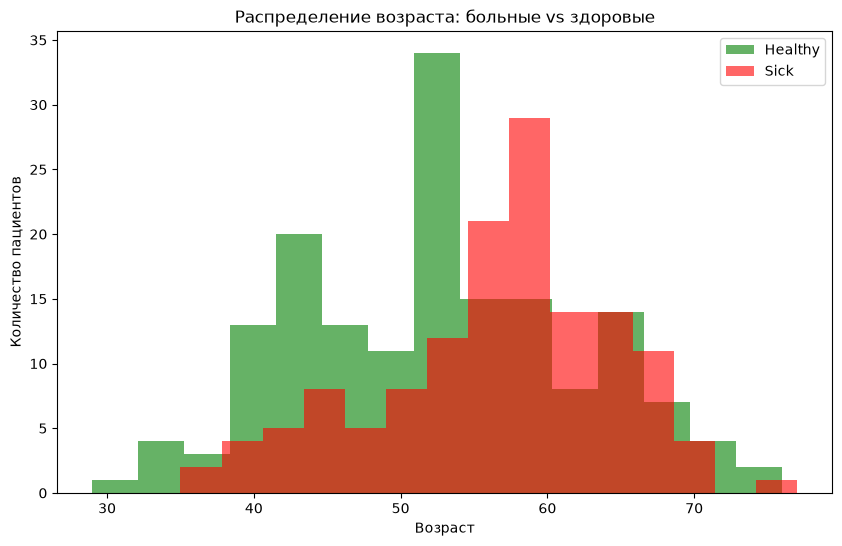

In [42]:
plt.figure(figsize=(10, 6))
plt.hist(df[df['disease']==0]['age'], bins=15, alpha=0.6, label='Healthy', color='green')
plt.hist(df[df['disease']==1]['age'], bins=15, alpha=0.6, label='Sick', color='red')
plt.xlabel('Возраст')
plt.ylabel('Количество пациентов')
plt.title('Распределение возраста: больные vs здоровые')
plt.legend()
plt.savefig('../figures/01_age_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

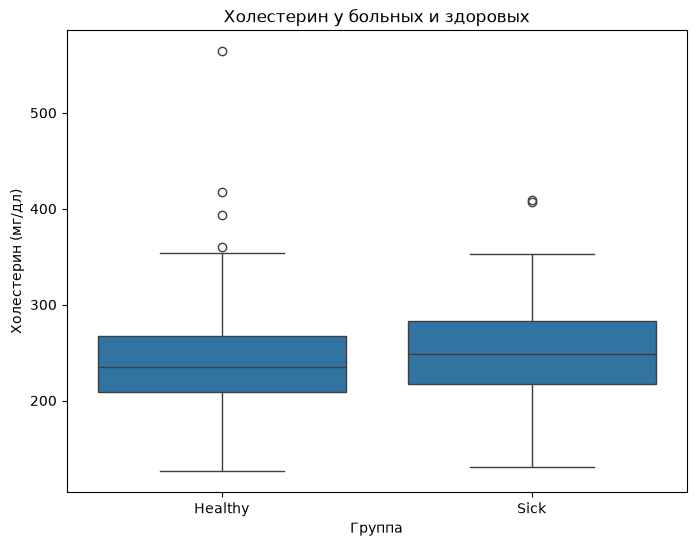

In [43]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='disease', y='chol', data=df)
plt.xticks([0, 1], ['Healthy', 'Sick'])
plt.xlabel('Группа')
plt.ylabel('Холестерин (мг/дл)')
plt.title('Холестерин у больных и здоровых')
plt.savefig('../figures/02_chol_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

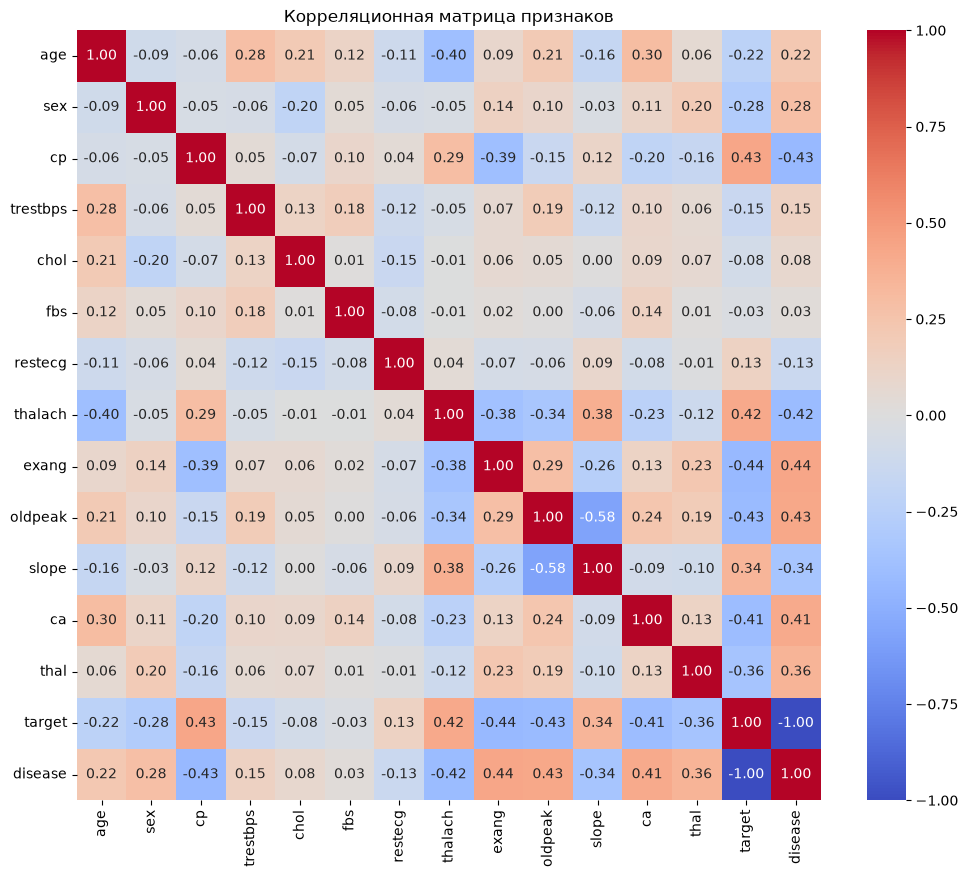

In [44]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Корреляционная матрица признаков')
plt.savefig('../figures/03_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

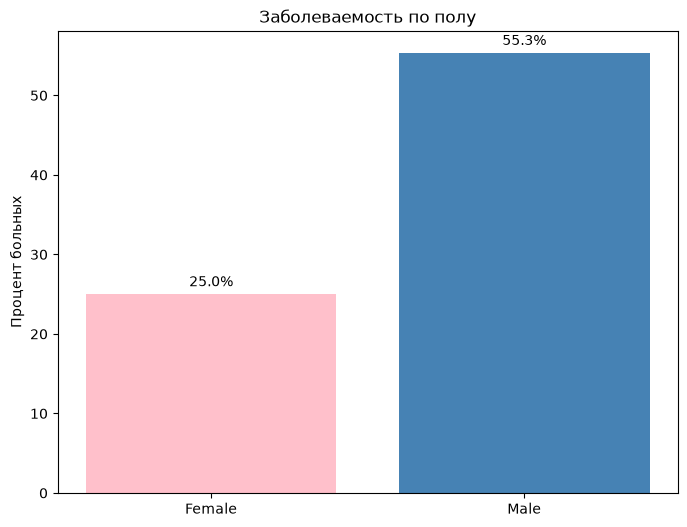

In [45]:
sex_data = df.groupby('sex')['disease'].mean() * 100

plt.figure(figsize=(8, 6))
plt.bar(['Female', 'Male'], sex_data.values, color=['pink', 'steelblue'])
plt.ylabel('Процент больных')
plt.title('Заболеваемость по полу')
for i, v in enumerate(sex_data.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.savefig('../figures/04_sex_rate.png', dpi=150, bbox_inches='tight')
plt.show()

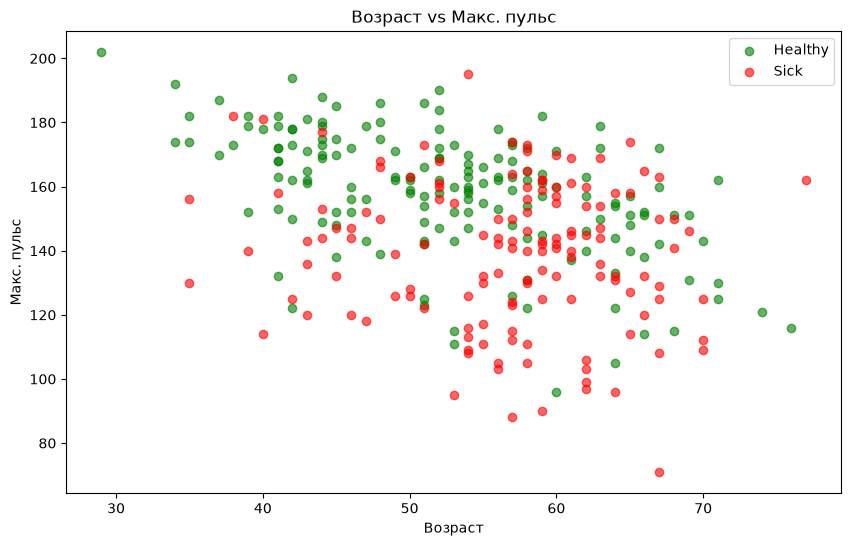

In [46]:
plt.figure(figsize=(10, 6))
plt.scatter(df[df['disease']==0]['age'], df[df['disease']==0]['thalach'], 
            alpha=0.6, label='Healthy', color='green')
plt.scatter(df[df['disease']==1]['age'], df[df['disease']==1]['thalach'], 
            alpha=0.6, label='Sick', color='red')
plt.xlabel('Возраст')
plt.ylabel('Макс. пульс')
plt.title('Возраст vs Макс. пульс')
plt.legend()
plt.savefig('../figures/05_age_vs_thalach.png', dpi=150, bbox_inches='tight')
plt.show()

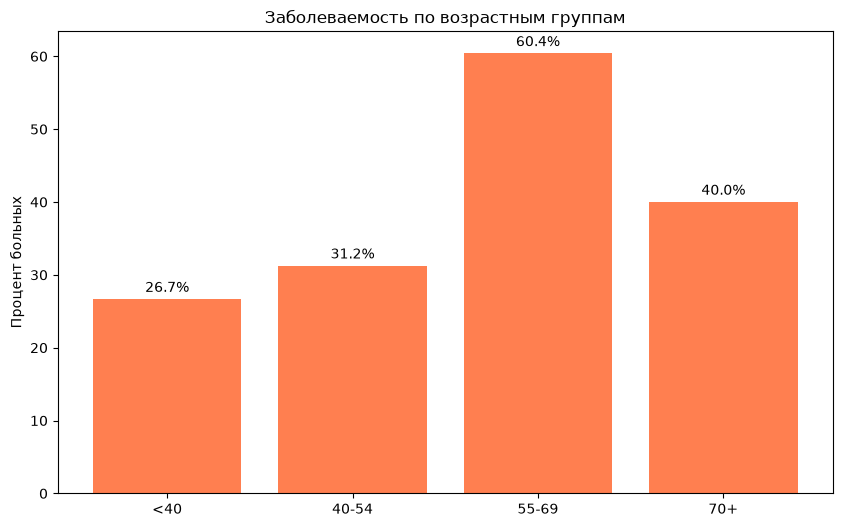

In [47]:
df['age_group'] = pd.cut(df['age'], 
                          bins=[0, 40, 55, 70, 100], 
                          labels=['<40', '40-54', '55-69', '70+'],
                          right=False)

age_stats = df.groupby('age_group', observed=True)['disease'].mean() * 100

plt.figure(figsize=(10, 6))
plt.bar(age_stats.index.astype(str), age_stats.values, color='coral')
plt.ylabel('Процент больных')
plt.title('Заболеваемость по возрастным группам')
for i, v in enumerate(age_stats.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.savefig('../figures/06_age_group_rate.png', dpi=150, bbox_inches='tight')
plt.show()

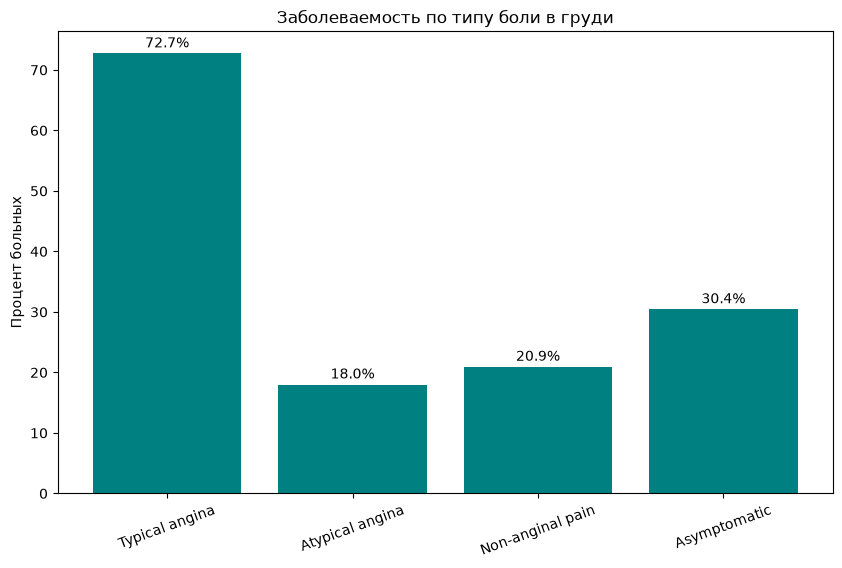

In [48]:
cp_labels = {0: 'Typical angina', 1: 'Atypical angina', 
             2: 'Non-anginal pain', 3: 'Asymptomatic'}
cp_data = df.groupby('cp')['disease'].mean() * 100

plt.figure(figsize=(10, 6))
bars = plt.bar([cp_labels[i] for i in cp_data.index], cp_data.values, color='teal')
plt.ylabel('Процент больных')
plt.title('Заболеваемость по типу боли в груди')
plt.xticks(rotation=20)
for i, v in enumerate(cp_data.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.savefig('../figures/07_chest_pain_rate.png', dpi=150, bbox_inches='tight')
plt.show()

# Выводы

## Основные инсайты

1. **Пол:** мужчины болеют в 2.2 раза чаще женщин (55.3% vs 25.0%).
2. **Возраст:** критическая группа — 55–69 лет (заболеваемость 60.4%).
3. **Пульс:** у больных максимальный пульс ниже (139.1 vs 158.4 уд/мин).
4. **Холестерин:** у больных выше (251.1 vs 242.6 мг/дл).
5. **ЭКГ (oldpeak):** у больных значение в 2.7 раза выше (1.59 vs 0.59).
6. **Тип боли:** типичная стенокардия — самый сильный предиктор (72.7%).
7. **Ключевые предикторы:** exang, oldpeak, ca, thalach, cp.

## Обнаруженная проблема данных

В исходном датасете метки `target` были **инвертированы**: 
`target=0` означал больного, `target=1` — здорового. 
Мы это обнаружили при анализе корреляций и исправили, 
создав корректную переменную `disease`.

## Ограничения

- Датасет небольшой (302 записи).
- Данные 1988 года (Кливленд) — не отражают современность.
- Нет данных об образе жизни (курение, питание, спорт).
- Корреляция ≠ причинность.

## Перспективы

- Проверка гипотез на современных данных.
- Построение ML-модели для предсказания риска.
- Расширение датасета факторами образа жизни.